# 01 - Data Preparation
## Breast Cancer Wisconsin (Diagnostic) Dataset

This notebook covers:
- **Section A:** Load and inspect the dataset
- **Section B:** Exploratory Data Analysis (EDA)
- **Section C:** Preprocessing (scaling, train/test split)
- **Section D:** Validation of splits and saved artifacts

In [ ]:
import os
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

# Resolve repo root relative to this notebook's location.
# Works on local machines, VMs, and Colab alike.
try:
    # When running inside a Jupyter notebook, __vsc_ipynb_file__ or
    # the ipynbname package may provide the path. Fall back to cwd.
    _vsc = globals().get('__vsc_ipynb_file__', '')
    if not _vsc:
        raise ValueError
    _nb_dir = pathlib.Path(_vsc).parent
    if not _nb_dir.exists():
        raise ValueError
except (TypeError, ValueError, OSError):
    _nb_dir = pathlib.Path.cwd()

# If we are inside a 'notebooks' folder, go one level up to reach the repo root.
# Otherwise assume cwd IS the repo root (e.g. Colab after cloning).
REPO_ROOT = str(_nb_dir.parent) if _nb_dir.name == 'notebooks' else str(_nb_dir)

DATA_DIR  = os.path.join(REPO_ROOT, 'data')
MODEL_DIR = os.path.join(REPO_ROOT, 'model')

# Create directories only if they don't already exist
for d in [DATA_DIR, MODEL_DIR]:
    pathlib.Path(d).mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.2

print(f"Repo root: {REPO_ROOT}")
print(f"Data dir:  {DATA_DIR}")
print(f"Model dir: {MODEL_DIR}")

## Section A: Load and Inspect Data

In [2]:
# Load the Breast Cancer Wisconsin (Diagnostic) dataset
data = load_breast_cancer(as_frame=True)
df = data.frame                              # 569 rows x 31 columns
feature_cols = data.feature_names.tolist()   # 30 feature name strings
target_col = 'target'

print(f"Shape: {df.shape}")
print(f"Number of features: {len(feature_cols)}")
print(f"Target column: '{target_col}'")
print(f"Target classes: {df[target_col].unique()} (0=Malignant, 1=Benign)")
print()
df.head()

Shape: (569, 31)
Number of features: 30
Target column: 'target'
Target classes: [0 1] (0=Malignant, 1=Benign)



,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Data types
print("Data types:")
print(df.dtypes)
print()

# Summary statistics
df.describe()

Data types:
mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst sy

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [4]:
# Target class distribution
print("Target class distribution:")
print(df[target_col].value_counts())
print()
print("Proportions:")
print(df[target_col].value_counts(normalize=True).round(3))

Target class distribution:
target
1    357
0    212
Name: count, dtype: int64

Proportions:
target
1    0.627
0    0.373
Name: proportion, dtype: float64


In [5]:
# Verification checks (Step 2 assertions)
assert df.shape[0] >= 500, f"FAIL: instances ({df.shape[0]}) < 500"
assert len(feature_cols) >= 12, f"FAIL: features ({len(feature_cols)}) < 12"
assert df[target_col].nunique() == 2, f"FAIL: not binary classification (classes={df[target_col].nunique()})"

print("All Step 2 verification checks PASSED")
print(f"  Instances: {df.shape[0]} (>= 500)")
print(f"  Features:  {len(feature_cols)} (>= 12)")
print(f"  Classes:   {df[target_col].nunique()} (== 2, binary)")

All Step 2 verification checks PASSED
  Instances: 569 (>= 500)
  Features:  30 (>= 12)
  Classes:   2 (== 2, binary)


## Section B: Exploratory Data Analysis (EDA)

In [6]:
# Missing values
print("Missing values per column:")
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "None (0 missing values across all columns)")
print(f"\nTotal missing values: {missing.sum()}")

# Duplicate rows
n_duplicates = df.duplicated().sum()
print(f"\nDuplicate rows: {n_duplicates}")

Missing values per column:
None (0 missing values across all columns)

Total missing values: 0

Duplicate rows: 0


findfont: Failed to find font weight bold for DejaVu Sans, now using 400.


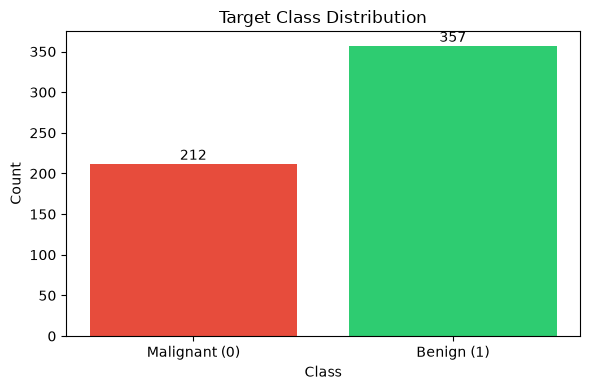

In [7]:
# Class distribution bar chart
fig, ax = plt.subplots(figsize=(6, 4))
class_counts = df[target_col].value_counts()
bars = ax.bar(['Malignant (0)', 'Benign (1)'], [class_counts[0], class_counts[1]],
              color=['#e74c3c', '#2ecc71'])
for bar, count in zip(bars, [class_counts[0], class_counts[1]]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
            str(count), ha='center', fontweight='bold')
ax.set_xlabel('Class')
ax.set_ylabel('Count')
ax.set_title('Target Class Distribution')
plt.tight_layout()
plt.show()

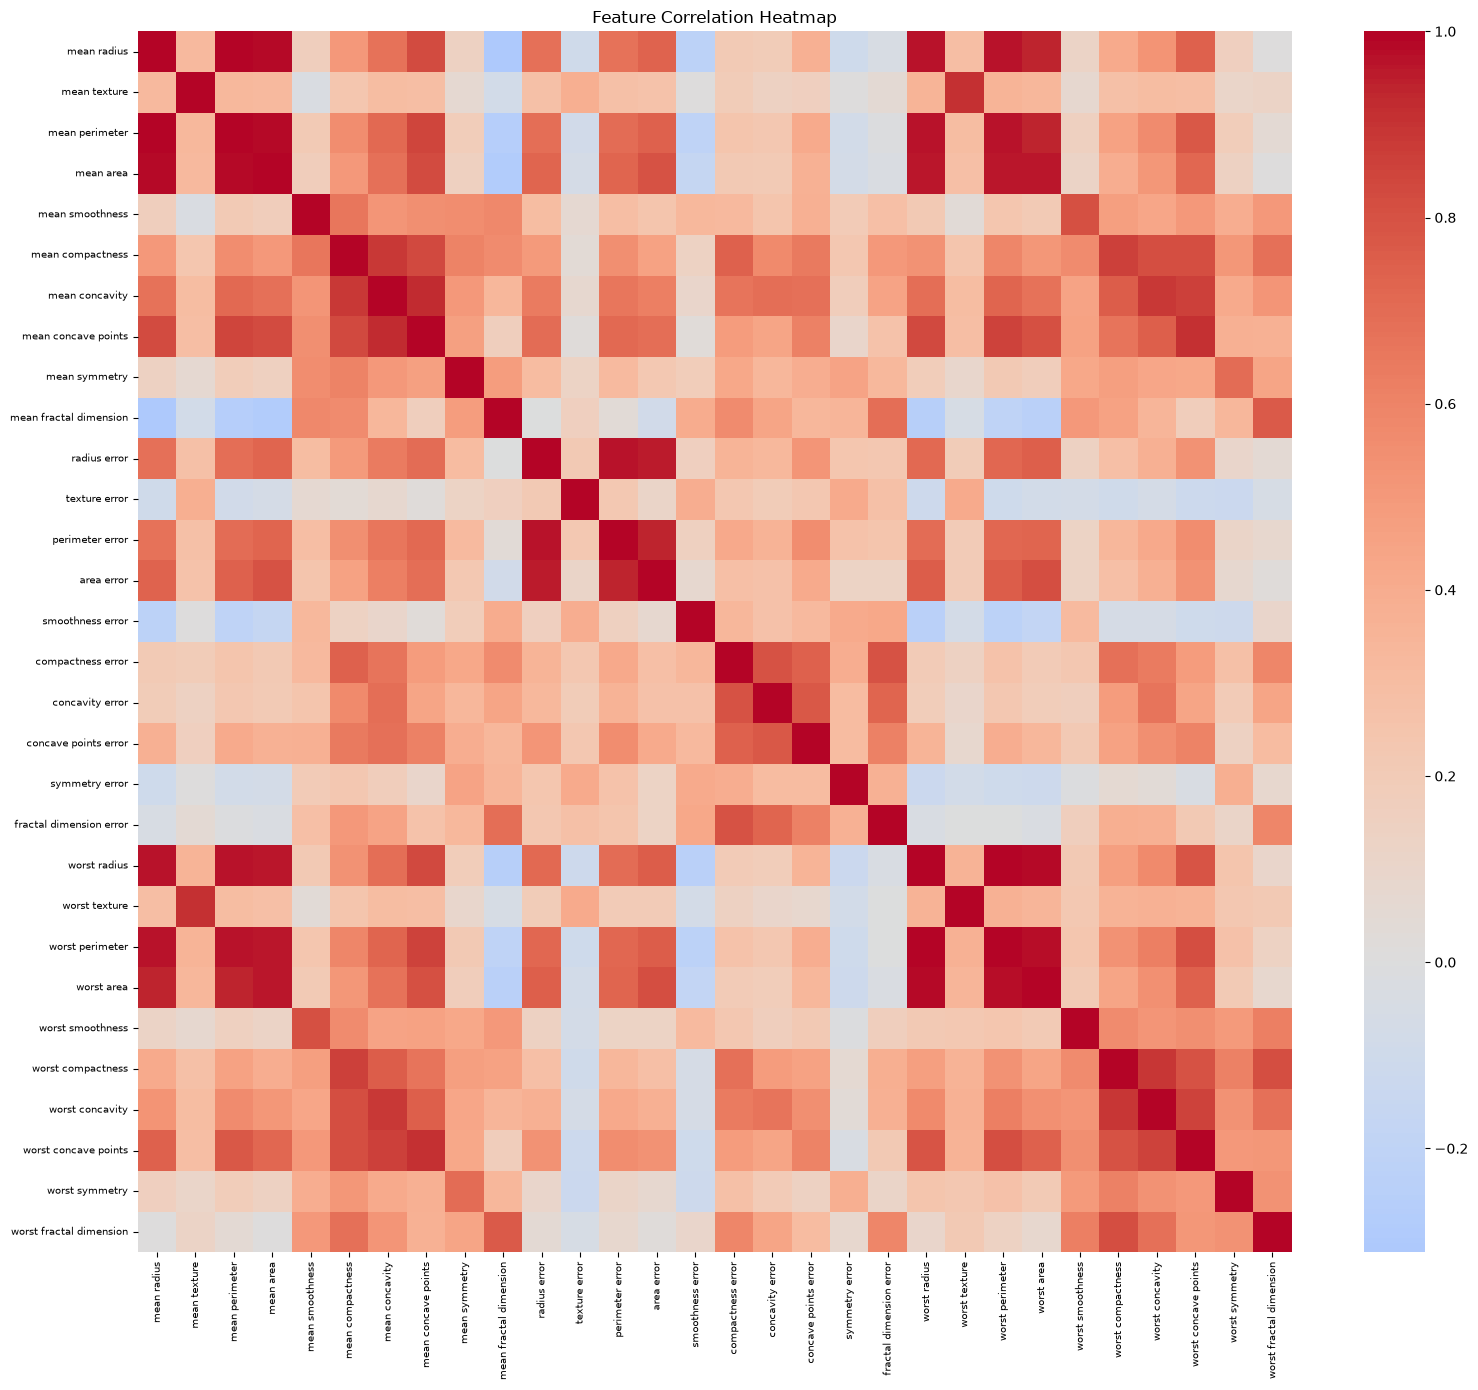

In [8]:
# Feature correlation heatmap
fig, ax = plt.subplots(figsize=(16, 14))
corr_matrix = df[feature_cols].corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0, ax=ax,
            xticklabels=True, yticklabels=True)
ax.set_title('Feature Correlation Heatmap')
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()

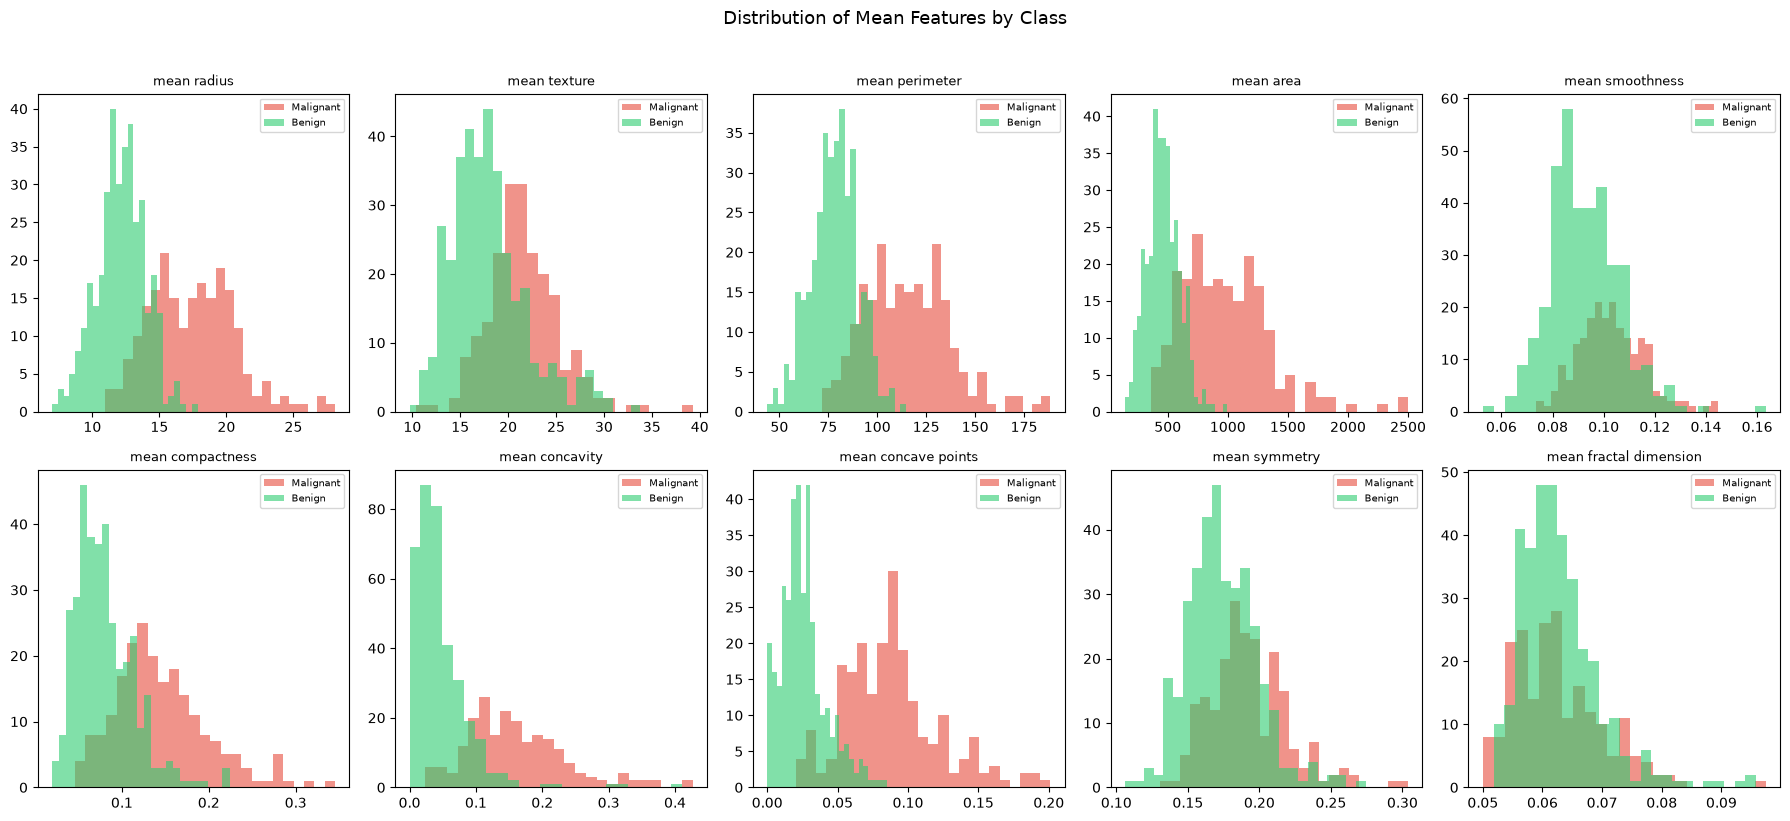

In [9]:
# Distribution histograms for key features (mean features)
mean_features = [c for c in feature_cols if c.startswith('mean')]
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, col in zip(axes.ravel(), mean_features):
    for label, color in [(0, '#e74c3c'), (1, '#2ecc71')]:
        subset = df[df[target_col] == label][col]
        ax.hist(subset, bins=25, alpha=0.6, color=color,
                label='Malignant' if label == 0 else 'Benign')
    ax.set_title(col, fontsize=9)
    ax.legend(fontsize=7)
fig.suptitle('Distribution of Mean Features by Class', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [10]:
# Highly correlated feature pairs (|r| > 0.9)
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.9:
            high_corr_pairs.append(
                (corr_matrix.columns[i], corr_matrix.columns[j],
                 round(corr_matrix.iloc[i, j], 3))
            )

print(f"Feature pairs with |correlation| > 0.9: {len(high_corr_pairs)}")
for f1, f2, r in sorted(high_corr_pairs, key=lambda x: -abs(x[2])):
    print(f"  {f1:30s} <-> {f2:30s}  r = {r}")

Feature pairs with |correlation| > 0.9: 21
  mean radius                    <-> mean perimeter                  r = 0.998
  worst radius                   <-> worst perimeter                 r = 0.994
  mean radius                    <-> mean area                       r = 0.987
  mean perimeter                 <-> mean area                       r = 0.987
  worst radius                   <-> worst area                      r = 0.984
  worst perimeter                <-> worst area                      r = 0.978
  radius error                   <-> perimeter error                 r = 0.973
  mean radius                    <-> worst radius                    r = 0.97
  mean perimeter                 <-> worst perimeter                 r = 0.97
  mean perimeter                 <-> worst radius                    r = 0.969
  mean radius                    <-> worst perimeter                 r = 0.965
  mean area                      <-> worst radius                    r = 0.963
  mean area

In [11]:
# Generate EDA summary markdown
eda_lines = [
    "# EDA Summary - Breast Cancer Wisconsin (Diagnostic)",
    "",
    "## Dataset Overview",
    f"- **Source:** `sklearn.datasets.load_breast_cancer()`",
    f"- **Instances:** {df.shape[0]}",
    f"- **Features:** {len(feature_cols)} (all continuous float64)",
    f"- **Target:** binary (0 = Malignant, 1 = Benign)",
    "",
    "## Class Distribution",
    f"- Malignant (0): {class_counts[0]} ({class_counts[0]/len(df)*100:.1f}%)",
    f"- Benign (1): {class_counts[1]} ({class_counts[1]/len(df)*100:.1f}%)",
    f"- Mildly imbalanced; stratified split used to maintain ratio.",
    "",
    "## Missing Values",
    f"- Total missing values: {missing.sum()} (none)",
    f"- No imputation needed.",
    "",
    "## Duplicate Rows",
    f"- Duplicate rows: {n_duplicates}",
    "",
    "## Feature Ranges",
    "Features have vastly different scales:",
    f"- `mean area` ranges from {df['mean area'].min():.1f} to {df['mean area'].max():.1f}",
    f"- `mean smoothness` ranges from {df['mean smoothness'].min():.4f} to {df['mean smoothness'].max():.4f}",
    "- StandardScaler is essential for distance-based models (SVM, KNN).",
    "",
    "## Highly Correlated Features",
    f"- {len(high_corr_pairs)} feature pairs with |r| > 0.9",
    "- Examples: radius, perimeter, and area are highly correlated (r > 0.99)",
    "- PCA/feature selection skipped as not required by the assignment.",
    "",
    "## Key Observations",
    "- All features are numeric (float64); no encoding needed.",
    "- Malignant tumors tend to have larger mean radius, area, and perimeter.",
    "- `mean concave points` and `worst concave points` show strong class separation.",
]

eda_summary = "\n".join(eda_lines)
eda_path = os.path.join(DATA_DIR, 'eda_summary.md')
with open(eda_path, 'w') as f:
    f.write(eda_summary)

print(f"EDA summary saved to: {eda_path}")

EDA summary saved to: c:\Users\Ruman_Shareef\OneDrive - Dell Technologies\Desktop\BITSPilani\FirstSem\ML\assignments\assignment2\data\eda_summary.md


## Section C: Preprocessing

- **Scaling:** StandardScaler (zero-mean, unit-variance) — essential for SVM/KNN
- **Encoding:** Not needed (all features are float64)
- **Missing values:** None to handle
- **Split:** 80/20 train/test, stratified on target, random_state=42

In [12]:
# Step 1: Separate features and target
X = df[feature_cols]   # (569, 30)
y = df[target_col]     # (569,)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

# Step 2: Train/test split (80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"\nTrain set: {X_train.shape[0]} samples")
print(f"Test set:  {X_test.shape[0]} samples")
print(f"\nTrain class distribution:")
print(y_train.value_counts())
print(f"\nTest class distribution:")
print(y_test.value_counts())

X shape: (569, 30)
y shape: (569,)

Train set: 455 samples
Test set:  114 samples

Train class distribution:
target
1    285
0    170
Name: count, dtype: int64

Test class distribution:
target
1    72
0    42
Name: count, dtype: int64


In [13]:
# Step 3: Fit StandardScaler on training data ONLY (no data leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaler fitted on training data only.")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape:  {X_test_scaled.shape}")
print(f"\nTrain feature means (should be ~0): {X_train_scaled.mean(axis=0)[:5].round(6)}")
print(f"Train feature stds  (should be ~1): {X_train_scaled.std(axis=0)[:5].round(6)}")

Scaler fitted on training data only.
X_train_scaled shape: (455, 30)
X_test_scaled shape:  (114, 30)

Train feature means (should be ~0): [-0.  0. -0.  0.  0.]
Train feature stds  (should be ~1): [1. 1. 1. 1. 1.]


In [14]:
# Step 4: Save the fitted scaler
scaler_path = os.path.join(MODEL_DIR, 'preprocessor.pkl')
joblib.dump(scaler, scaler_path)
print(f"Preprocessor saved: {scaler_path}")

# Step 5: Save scaled splits as CSV (column names preserved)
X_train_df = pd.DataFrame(X_train_scaled, columns=feature_cols)
X_test_df = pd.DataFrame(X_test_scaled, columns=feature_cols)
y_train_series = y_train.reset_index(drop=True)
y_test_series = y_test.reset_index(drop=True)

X_train_df.to_csv(os.path.join(DATA_DIR, 'X_train.csv'), index=False)
y_train_series.to_csv(os.path.join(DATA_DIR, 'y_train.csv'), index=False)
X_test_df.to_csv(os.path.join(DATA_DIR, 'X_test.csv'), index=False)
y_test_series.to_csv(os.path.join(DATA_DIR, 'y_test.csv'), index=False)

print(f"X_train.csv saved: {X_train_df.shape}")
print(f"y_train.csv saved: {y_train_series.shape}")
print(f"X_test.csv saved:  {X_test_df.shape}")
print(f"y_test.csv saved:  {y_test_series.shape}")

Preprocessor saved: c:\Users\Ruman_Shareef\OneDrive - Dell Technologies\Desktop\BITSPilani\FirstSem\ML\assignments\assignment2\model\preprocessor.pkl
X_train.csv saved: (455, 30)
y_train.csv saved: (455,)
X_test.csv saved:  (114, 30)
y_test.csv saved:  (114,)


In [15]:
# Step 6: Build test_data.csv (RAW/unscaled features + target) for Streamlit upload
# Use original unscaled test features so Streamlit app can apply preprocessor.pkl
X_test_raw = df.loc[X_test.index, feature_cols].reset_index(drop=True)
y_test_raw = y_test.reset_index(drop=True)
test_df = pd.concat([X_test_raw, y_test_raw], axis=1)

test_data_path = os.path.join(REPO_ROOT, 'test_data.csv')
test_df.to_csv(test_data_path, index=False)

print(f"test_data.csv saved: {test_df.shape}")
print(f"Columns: {list(test_df.columns[:5])} ... + target ({test_df.shape[1]} total)")
print(f"Path: {test_data_path}")
test_df.head()

test_data.csv saved: (114, 31)
Columns: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness'] ... + target (31 total)
Path: c:\Users\Ruman_Shareef\OneDrive - Dell Technologies\Desktop\BITSPilani\FirstSem\ML\assignments\assignment2\test_data.csv


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,19.55,28.77,133.60,1207.0,0.09260,0.20630,0.17840,0.11440,0.1893,0.06232,...,36.27,178.60,1926.0,0.1281,0.53290,0.4251,0.19410,0.2818,0.10050,0
1,11.13,16.62,70.47,381.1,0.08151,0.03834,0.01369,0.01370,0.1511,0.06148,...,20.29,74.35,421.1,0.1030,0.06219,0.0458,0.04044,0.2383,0.07083,1
2,13.82,24.49,92.33,595.9,0.11620,0.16810,0.13570,0.06759,0.2275,0.07237,...,32.94,106.00,788.0,0.1794,0.39660,0.3381,0.15210,0.3651,0.11830,0
3,16.50,18.29,106.60,838.1,0.09686,0.08468,0.05862,0.04835,0.1495,0.05593,...,25.45,117.20,1009.0,0.1338,0.16790,0.1663,0.09123,0.2394,0.06469,1
4,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.1410,0.21130,0.4107,0.22160,0.2060,0.07115,0


## Section D: Validation

Verify all deliverables and exit criteria.

In [16]:
# Validation: Shape checks
print("=== Split Shape Validation ===")
print(f"X_train: {X_train_df.shape}")
print(f"X_test:  {X_test_df.shape}")
print(f"y_train: {y_train_series.shape}")
print(f"y_test:  {y_test_series.shape}")

assert X_train_df.shape[0] > X_test_df.shape[0], "FAIL: train should be larger than test"
assert X_test_df.shape[1] == X_train_df.shape[1], "FAIL: train and test must have same features"
print("Shape checks PASSED")

# Validation: test_data.csv
print("\n=== test_data.csv Validation ===")
test_loaded = pd.read_csv(test_data_path)
print(f"Shape: {test_loaded.shape}")
assert 'target' in test_loaded.columns, "FAIL: 'target' column missing from test_data.csv"
assert test_loaded.shape[1] == 31, f"FAIL: expected 31 columns, got {test_loaded.shape[1]}"
print("test_data.csv checks PASSED")

# Validation: preprocessor.pkl
print("\n=== preprocessor.pkl Validation ===")
assert os.path.exists(scaler_path), f"FAIL: {scaler_path} not found"
loaded_scaler = joblib.load(scaler_path)
print(f"Loaded scaler type: {type(loaded_scaler).__name__}")
# Verify loaded scaler produces same results
test_transform = loaded_scaler.transform(X_test.iloc[:1])
print(f"Scaler works: transformed shape = {test_transform.shape}")
print("preprocessor.pkl checks PASSED")

# Validation: All CSV files exist
print("\n=== CSV Files Validation ===")
for fname in ['X_train.csv', 'y_train.csv', 'X_test.csv', 'y_test.csv']:
    fpath = os.path.join(DATA_DIR, fname)
    assert os.path.exists(fpath), f"FAIL: {fpath} not found"
    print(f"  {fname}: EXISTS")
print("CSV files checks PASSED")

# Validation: EDA summary
assert os.path.exists(eda_path), f"FAIL: {eda_path} not found"
print(f"\n  eda_summary.md: EXISTS")

print("\n" + "=" * 50)
print("ALL VALIDATION CHECKS PASSED")
print("=" * 50)

=== Split Shape Validation ===
X_train: (455, 30)
X_test:  (114, 30)
y_train: (455,)
y_test:  (114,)
Shape checks PASSED

=== test_data.csv Validation ===
Shape: (114, 31)
test_data.csv checks PASSED

=== preprocessor.pkl Validation ===
Loaded scaler type: StandardScaler
Scaler works: transformed shape = (1, 30)
preprocessor.pkl checks PASSED

=== CSV Files Validation ===
  X_train.csv: EXISTS
  y_train.csv: EXISTS
  X_test.csv: EXISTS
  y_test.csv: EXISTS
CSV files checks PASSED

  eda_summary.md: EXISTS

ALL VALIDATION CHECKS PASSED
